###PyTorch Computer Vision

In [ ]:
#import pytorch
import torch
from torch import nn

#import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# import matplotlib for visualization
import matplotlib.pyplot as plt

print(torch.__version__)
print(torchvision.__version__)

2.1.0+cu121
0.16.0+cu121


###Getting a dataset


In [ ]:
 #setup training data
from torchvision import datasets
train_data = datasets.FashionMNIST(
    root = "data",
    train = True,
    download = True,
    transform = torchvision.transforms.ToTensor(),
    target_transform = None
)

test_data = datasets.FashionMNIST(
    root = "data",
    train = False,
    download = True,
    transform = torchvision.transforms.ToTensor(),
    target_transform = None
)

100%|██████████| 26421880/26421880 [00:02<00:00, 10654856.51it/s]


Extracting data/FashionMNIST/raw/train-images-idx3-ubyte.gz to data/FashionMNIST/raw



100%|██████████| 29515/29515 [00:00<00:00, 203165.91it/s]


Extracting data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to data/FashionMNIST/raw



100%|██████████| 4422102/4422102 [00:01<00:00, 3723613.71it/s]


Extracting data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to data/FashionMNIST/raw



100%|██████████| 5148/5148 [00:00<00:00, 5569326.02it/s]

Extracting data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to data/FashionMNIST/raw



In [ ]:
len(train_data), len(test_data)

(60000, 10000)

In [ ]:
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
train_data.classes

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [ ]:
train_data.class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [ ]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [ ]:
train_data.data

tensor([[[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        ...,

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0,

In [ ]:
#check shape of input and output
print(f"Image shape : {image.shape}")
print(f"Image label : {train_data.classes[label]}")

Image shape : torch.Size([1, 28, 28])
Image label : Ankle boot


Image shape : torch.Size([1, 28, 28])
Image label : Ankle boot


Text(0.5, 1.0, '9')

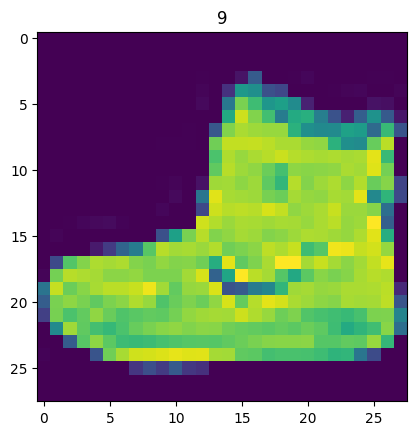

In [ ]:
image, label = train_data[0]
print(f"Image shape : {image.shape}")
print(f"Image label : {train_data.classes[label]}")
plt.imshow(image.squeeze())
plt.title(label)

(-0.5, 27.5, 27.5, -0.5)

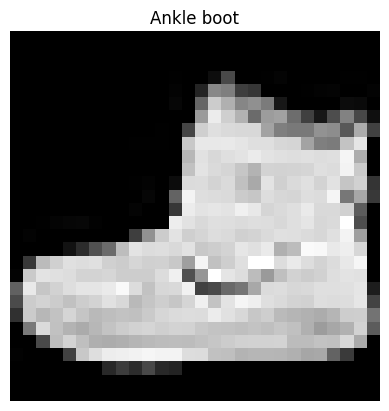

In [ ]:
plt.imshow(image.squeeze(), cmap = "gray")
plt.title(train_data.classes[label])
plt.axis(False)

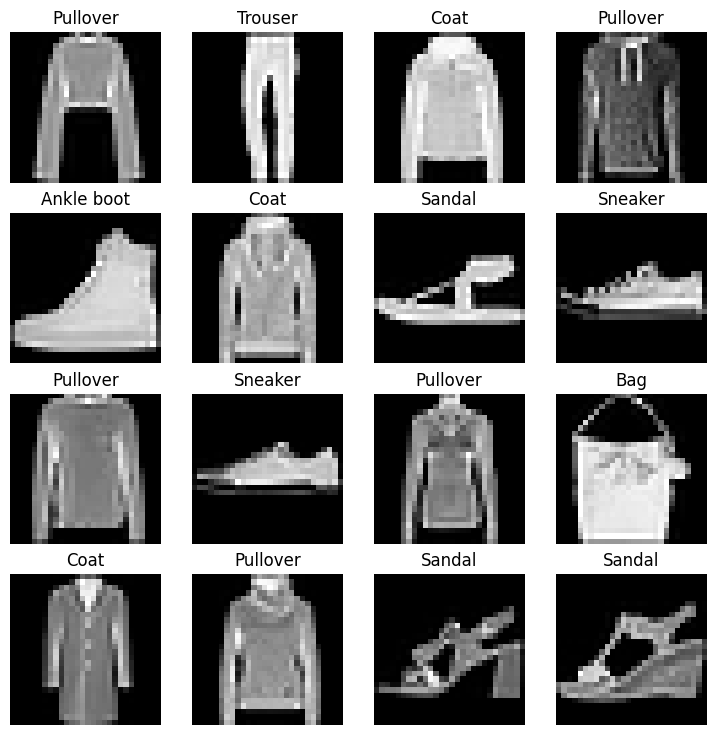

In [ ]:
#plot more images
fig = plt.figure(figsize = (9,9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
  random_idx = torch.randint(0,len(train_data), size = [1]).item()
  # print(random_idx)
  img, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.imshow(img.squeeze(), cmap = "gray")
  plt.title(train_data.classes[label])
  plt.axis(False)

###Prepare DataLoader

In [ ]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32

train_dataloader = DataLoader(dataset = train_data,
                              batch_size = BATCH_SIZE,
                              shuffle = True)
test_dataloader = DataLoader(dataset = test_data,
                             batch_size = BATCH_SIZE,
                             shuffle = False)

In [ ]:
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x784016cf1a80>,
 <torch.utils.data.dataloader.DataLoader at 0x784016cf3e50>)

In [ ]:
print(f"Length : {len(train_dataloader)} of batches {BATCH_SIZE}")
print(f"Length : {len(test_dataloader)} of batches {BATCH_SIZE}")

Length : 1875 of batches 32
Length : 313 of batches 32


In [ ]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size : torch.Size([1, 28, 28])
Label : 2 label size :torch.Size([])


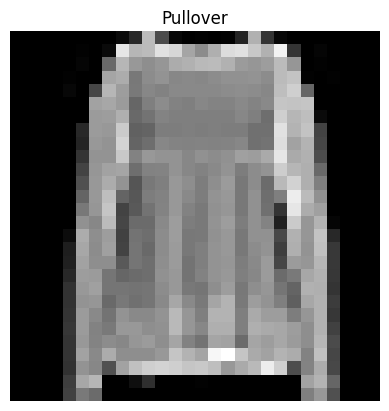

In [ ]:
#show a sample
random_idx = torch.randint(0, len(train_features_batch), size = [1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap = "gray")
plt.title(train_data.classes[label])
plt.axis(False)
print(f"Image size : {img.shape}")
print(f"Label : {label} label size :{label.shape}")

###Model 0 : build a baseline model

In [ ]:
flatten_model = nn.Flatten()
x = train_features_batch[0]
output = flatten_model(x)
print(f"shape before flattening : {x.shape}")
print(f"shape after flattening : {output.shape}")

shape before flattening : torch.Size([1, 28, 28])
shape after flattening : torch.Size([1, 784])


In [ ]:
x[0][0]

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.])

In [ ]:
output

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0

In [ ]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
  def __init__(self, input_shape : int, hidden_units : int, output_shape : int):
    super().__init__()
    self.linear_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = input_shape, out_features = hidden_units),
        nn.Linear(in_features = hidden_units, out_features = output_shape)
    )

  def forward(self,x):
    return self.linear_stack(x)

In [ ]:
torch.manual_seed(42)

#setup model with input parameters
model_0 = FashionMNISTModelV0(
    input_shape = 784, #this is 28 * 28
    hidden_units = 10,
    output_shape = len(train_data.classes)
).to("cpu")
model_0

FashionMNISTModelV0(
  (linear_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [ ]:
dummy_x = torch.rand(1,1,28,28)
model_0(dummy_x).shape

torch.Size([1, 10])

In [ ]:
model_0.state_dict()

OrderedDict([('linear_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('linear_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('linear_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, 

#Setup loss function, optimizer and evaluation metrics

In [ ]:
import requests
from pathlib import Path

if Path("helper_functions.py").is_file():
  print(f"File already exists, skipping download...")
else :
  print(f"Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.1)

###Creating a function to time our experiments

In [ ]:
from timeit import default_timer as timer
def print_train_time(start : float,
                     end : float,
                     device : torch.device = None):
  total_time = end - start
  print(f"Train time on {device} : {total_time : .3f} seconds")
  return total_time

In [ ]:
start_time = timer()

end_time = timer()
print_train_time(start = start_time, end = end_time, device = "cpu")

Train time on cpu :  0.000 seconds


4.830999999683172e-05

###Creating a training loop and training a model on batches of data

In [ ]:
len(train_dataloader.dataset)


60000

In [ ]:
#Import tqdm for progress bar
from tqdm.auto import tqdm
#set the seed and start the timer
torch.manual_seed(42)
train_time_start_on_cpu = timer()

#Set the number of epochs
epochs = 3

#create a training and testing loop
for epoch in tqdm(range(epochs)):
  print(f"epoch : {epoch}\n-----")
  ###Training
  train_loss = 0
  #add a loop to loop through the training batches
  for batch, (X,y) in enumerate(train_dataloader):
    model_0.train()
    train_pred = model_0(X)
    loss = loss_fn(train_pred, y)
    train_loss += loss
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    #print out what's happening
    if batch % 400 == 0 :
      print(f"Looked at {batch * len(X)} / {len(train_dataloader.dataset)} samples.")

  #Divide total train loss by length of train dataloader
  train_loss = train_loss / len(train_dataloader)

  ###Testing
  test_loss, test_acc = 0,0
  model_0.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      test_pred = model_0(X_test)

      test_loss += loss_fn(test_pred, y_test)

      test_acc += accuracy_fn(y_true = y_test, y_pred = test_pred.argmax(dim = 1))

    #Calculate the test loss average per batch
    test_loss /= len(test_dataloader)

    #Calculate the test acc average per batch
    test_acc /= len(test_dataloader)

  #print out what's happening
  print(f"\nTrain loss : {train_loss: .4f} | Test loss : {test_loss : .4f} | Test accuracy : {test_acc : .4f}")

#Calculate training time
train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start = train_time_start_on_cpu,
                                            end = train_time_end_on_cpu,
                                            device = next(model_0.parameters()).device)




  0%|          | 0/3 [00:00<?, ?it/s]

epoch : 0
-----
Looked at 0 / 60000 samples.
Looked at 12800 / 60000 samples.
Looked at 25600 / 60000 samples.
Looked at 38400 / 60000 samples.
Looked at 51200 / 60000 samples.

Train loss :  0.5904 | Test loss :  0.5095 | Test accuracy :  82.0387
epoch : 1
-----
Looked at 0 / 60000 samples.
Looked at 12800 / 60000 samples.
Looked at 25600 / 60000 samples.
Looked at 38400 / 60000 samples.
Looked at 51200 / 60000 samples.

Train loss :  0.4763 | Test loss :  0.4799 | Test accuracy :  83.1969
epoch : 2
-----
Looked at 0 / 60000 samples.
Looked at 12800 / 60000 samples.
Looked at 25600 / 60000 samples.
Looked at 38400 / 60000 samples.
Looked at 51200 / 60000 samples.

Train loss :  0.4550 | Test loss :  0.4766 | Test accuracy :  83.4265
Train time on cpu :  41.658 seconds


In [ ]:
str(next(model_0.parameters()).device)

'cpu'

###Make predictions and get Model 0 results

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:

torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device : torch.device = device):
  """Returns a dictionary containing the results of model predicting on data_loader"""
  loss,acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X, y in tqdm(data_loader):
      X, y = X.to(device), y.to(device)
      y_pred = model(X)

      #Accumulate the loss and acc values per batch
      loss += loss_fn(y_pred, y)
      acc += accuracy_fn(y_true = y,
                         y_pred = y_pred.argmax(dim = 1))
    #Scale loss and acc to find the average loss/acc per batch
    loss /= len(data_loader)
    acc /= len(data_loader)

  return {"model_name" : model.__class__.__name__, #only works when model was created with a class
          "model_loss" : loss.item(),
          "model_acc" : acc}



In [ ]:
#calculate model_0 results
model_0_results = eval_model(model = model_0.to(device),
                             data_loader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn)
model_0_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

###Setup device agnostic code(for gpu if there is any)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

###Building a better model with non-linearity

In [ ]:
#Let's create a model with linear and non-linear layers
class FashionMNISTModelV1(nn.Module):
  def __init__(self,
               input_shape : int,
               hidden_units : int,
               output_shape : int):
    super().__init__()
    self.linear_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = input_shape,
                  out_features = hidden_units),
        nn.ReLU(),
        nn.Linear(in_features = hidden_units,
                  out_features = output_shape),
        nn.ReLU()
    )
  def forward(self, x):
    return self.linear_stack(x)

In [ ]:
#create an instance of model 1
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape = 784,
                              hidden_units = 10,
                              output_shape = len(train_data.classes)).to(device)
model_1

FashionMNISTModelV1(
  (linear_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

In [ ]:
dummy = torch.rand(1,1,28,28).to(device)
model_1(dummy)

tensor([[0.0806, 0.1593, 0.1565, 0.0000, 0.4741, 0.1441, 0.1634, 0.3834, 0.0000,
         0.0000]], device='cuda:0', grad_fn=<ReluBackward0>)

In [ ]:
next(model_1.parameters()).device

device(type='cuda', index=0)

###Pick loss function, optimizer and evaluation metrics

In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_1.parameters(),
                            lr = 0.1)

In [ ]:
loss_fn, optimizer

(CrossEntropyLoss(),
 SGD (
 Parameter Group 0
     dampening: 0
     differentiable: False
     foreach: None
     lr: 0.1
     maximize: False
     momentum: 0
     nesterov: False
     weight_decay: 0
 ))

###Functionizing training and testing/evaluation loops

In [ ]:
def train_step(model : torch.nn.Module,
               data_loader : torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               optimizer : torch.optim.Optimizer,
               accuracy_fn,
               device : torch.device = device):
  """Performs a training with model trying to learn on data_loader"""
  train_loss , train_acc = 0, 0

  #Put model into training mode
  model.train()

  #Add a loop to loop through the training batches
  for batch, (X,y) in enumerate(data_loader):
    #put data on target device
    X,y = X.to(device), y.to(device)

    train_pred = model(X)
    #calculate loss and accuracy per batch
    loss = loss_fn(train_pred, y)
    train_loss += loss
    train_acc += accuracy_fn(y_true = y,
                             y_pred = train_pred.argmax(dim = 1 ))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  #Divide total train loss and accuracy by length of train dataloader
  train_loss = train_loss / len(data_loader)
  train_acc = train_acc / len(data_loader)
  print(f"Train Loss : {train_loss: .5f} | Train Accuracy : {train_acc : .2f}%")



In [ ]:
def test_step(model : torch.nn.Module,
              data_loader : torch.utils.data.DataLoader,
              loss_fn : torch.nn.Module,
              accuracy_fn,
              device : torch.device = device
              ):
  """Performs testing step. """
  test_loss, test_acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X_test, y_test in data_loader:
      X_test, y_test = X_test.to(device), y_test.to(device)
      test_pred = model(X_test)

      test_loss += loss_fn(test_pred, y_test)

      test_acc += accuracy_fn(y_true = y_test, y_pred = test_pred.argmax(dim = 1))

    #Calculate the test loss average per batch
    test_loss /= len(data_loader)

    #Calculate the test acc average per batch
    test_acc /= len(data_loader)

  #print out what's happening
  print(f"Test loss : {test_loss : .5f} | Test accuracy : {test_acc : .2f}%")

###Train model_1 using the train and testing functions

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
#Measure time
from timeit import default_timer as timer
train_time_start_on_gpu = timer()
epochs = 3

for epoch in tqdm(range(epochs)):
  print(f"Epoch : {epoch}\n-------")
  train_step(model = model_1,
             data_loader = train_dataloader,
             loss_fn = loss_fn,
             optimizer = optimizer,
             accuracy_fn = accuracy_fn,
             device = device)
  test_step(model = model_1,
            data_loader = test_dataloader,
            loss_fn = loss_fn,
            accuracy_fn = accuracy_fn,
            device = device)
train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start = train_time_start_on_gpu,
                              end = train_time_end_on_gpu,
                                            device = device)
# print(f"Time taken to train : {total_time : .4f}")

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch : 0
-------
Train Loss :  1.09199 | Train Accuracy :  61.34%
Test loss :  0.95636 | Test accuracy :  65.00%
Epoch : 1
-------
Train Loss :  0.78101 | Train Accuracy :  71.93%
Test loss :  0.72227 | Test accuracy :  73.91%
Epoch : 2
-------
Train Loss :  0.67027 | Train Accuracy :  75.94%
Test loss :  0.68500 | Test accuracy :  75.02%
Train time on cuda :  33.340 seconds


In [ ]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [ ]:
total_train_time_model_0

41.657806625999996

In [ ]:
model_1_results = eval_model(model = model_1,
                             data_loader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn)
model_1_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850008964538574,
 'model_acc': 75.01996805111821}

In [ ]:
!nvidia-smi


Sun Mar 10 13:43:03 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   64C    P0              30W /  70W |    159MiB / 15360MiB |      3%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [ ]:
next(model_1.parameters()).device

device(type='cuda', index=0)

###Model 2 : Building a Convolutional Neral Network(CNN)



In [ ]:
class FashionMNISTModelV2(nn.Module):
  """
  Model architecture that replicates the TinyVGG
  model from CNN explainer website
  """
  def __init__(self,
               input_shape : int,
               hidden_units : int,
               output_shape : int):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels = input_shape,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )

    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)

    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = hidden_units * 7 *7,
                  out_features = output_shape)
    )

  def forward(self,x):
      x = self.conv_block_1(x)
      # print(x.shape)
      x = self.conv_block_2(x)
      # print(x.shape)
      x = self.classifier(x)
      # print(x.shape)
      return x


In [ ]:
len(train_data.classes)

10

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_2 = FashionMNISTModelV2(input_shape = 1,
                              hidden_units = 10,
                              output_shape = len(train_data.classes)).to(device)
model_2

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

###Stepping through nn.Conv2d()

In [ ]:
import torch

torch.manual_seed(42)
dummy = torch.randn(size = (32,3,64,64))
test_image = dummy[0]
print(f"Image batch shape : {dummy.shape}")
print(f"Single image shape : {test_image.shape}")
print(f"Test image\n : {test_image}")


Image batch shape : torch.Size([32, 3, 64, 64])
Single image shape : torch.Size([3, 64, 64])
Test image
 : tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [

In [ ]:
torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels = 3,
                        out_channels = 10,
                        kernel_size = 3,
                        stride = 1,
                        padding = 0)

a = conv_layer(test_image)
a.shape

torch.Size([10, 62, 62])

In [ ]:
test_image.shape

torch.Size([3, 64, 64])

###Stepping through nn.MaxPool2d()

In [ ]:
test_image.shape

torch.Size([3, 64, 64])

In [ ]:
#print out original image shape without unsqueezed dimension
print(f"Test image original shape : {test_image.shape}")
print(f"Test image with unsqueezed dimension : {test_image.unsqueeze(0).shape}") #in pytorch's previous version it was necessary, not anymore

max_pool_layer = nn.MaxPool2d(kernel_size = 2)

test_image_through_conv = conv_layer(test_image)

test_image_through_max_pool = max_pool_layer(test_image_through_conv)

print(f"shape of test image after conv layer : {test_image_through_conv.shape}")
print(f"shape of test image after conv and max pool : {test_image_through_max_pool.shape}")

Test image original shape : torch.Size([3, 64, 64])
Test image with unsqueezed dimension : torch.Size([1, 3, 64, 64])
shape of test image after conv layer : torch.Size([10, 62, 62])
shape of test image after conv and max pool : torch.Size([10, 31, 31])


In [ ]:
torch.manual_seed(42)

random_tensor = torch.randn(size = (1,2,2))
print(f"random_tensor :\n {random_tensor}")
print(f"random_tensor shape : {random_tensor.shape}")

max_pool = nn.MaxPool2d(kernel_size = 2)

max_pool_tensor = max_pool(random_tensor)
print(f"\nMax pool tensor : {max_pool_tensor}")
print(f"Max pool tensor shape : {max_pool_tensor.shape}")
print(f"dimension : {max_pool_tensor.ndim}")

random_tensor :
 tensor([[[0.3367, 0.1288],
         [0.2345, 0.2303]]])
random_tensor shape : torch.Size([1, 2, 2])

Max pool tensor : tensor([[[0.3367]]])
Max pool tensor shape : torch.Size([1, 1, 1])
dimension : 3


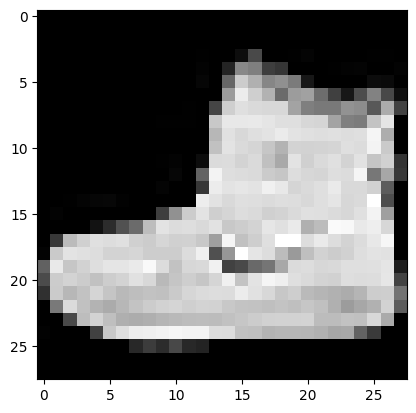

In [ ]:
plt.imshow(image.squeeze(), cmap = "gray")


In [ ]:
rand_image_tensor = torch.rand(size = (1,28,28))
model_2(rand_image_tensor.to(device))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10x49 and 490x10)

###Setup a loss function, eval metrics and optimizer for model 2


In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model_2.parameters(),
                            lr = 0.1)

###Testing and Training model_2 using training and testing functions

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#measure time
from timeit import default_timer as timer
train_time_start_model_2 = timer()

#train and test model
epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch : {epoch}")
  #training
  train_step(model = model_2,
             data_loader = train_dataloader,
             loss_fn = loss_fn,
             optimizer = optimizer,
             accuracy_fn = accuracy_fn,
             device = device)
  test_step(model = model_2,
            data_loader = test_dataloader,
            loss_fn = loss_fn,
            accuracy_fn = accuracy_fn,
            device = device)
train_time_end_model_2 = timer()
total_time_taken_model_2 = print_train_time(start = train_time_start_model_2,
                                            end = train_time_end_model_2,
                                            device = device)
total_time_taken_model_2

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch : 0
Train Loss :  0.59502 | Train Accuracy :  78.32%
Test loss :  0.40076 | Test accuracy :  85.49%
Epoch : 1
Train Loss :  0.36272 | Train Accuracy :  86.91%
Test loss :  0.34876 | Test accuracy :  87.09%
Epoch : 2
Train Loss :  0.32547 | Train Accuracy :  88.28%
Test loss :  0.32431 | Test accuracy :  88.21%
Train time on cuda :  40.002 seconds


40.002118035000024

In [ ]:
model_2_results = eval_model(model = model_2,
                             data_loader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn,
                             device = device)

  0%|          | 0/313 [00:00<?, ?it/s]

In [ ]:
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32431334257125854,
 'model_acc': 88.20886581469648}

In [ ]:
model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850008964538574,
 'model_acc': 75.01996805111821}

In [ ]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

###Compare model results and training time

In [ ]:
import pandas as pd
compare_results = pd.DataFrame([model_0_results,
                                model_1_results,
                                model_2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,83.426518
1,FashionMNISTModelV1,0.685001,75.019968
2,FashionMNISTModelV2,0.324313,88.208866


In [ ]:
compare_results["training_time"] = [total_train_time_model_0,
                                    total_train_time_model_1,
                                    total_time_taken_model_2]
compare_results

,model_name,model_loss,model_acc,training_time
0,FashionMNISTModelV0,0.476639,83.426518,41.657807
1,FashionMNISTModelV1,0.685001,75.019968,33.339926
2,FashionMNISTModelV2,0.324313,88.208866,40.002118


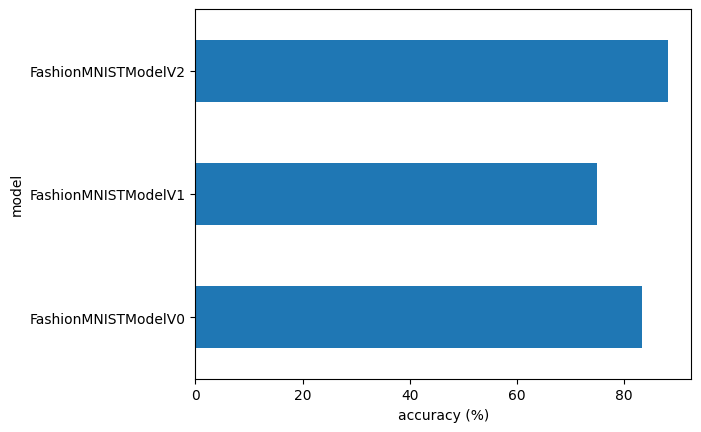

In [ ]:
compare_results.set_index("model_name")["model_acc"].plot(kind = "barh")
plt.xlabel("accuracy (%)")
plt.ylabel("model");

In [ ]:
###Make and evaluate random predictions with best model
def make_predictions(model: torch.nn.Module,
                     data : list,
                     device : torch.device = device):
  pred_probs = []
  model.to(device)
  model.eval()
  with torch.inference_mode():
      for sample in data:
        #prepare the sample (add a batch dimension and pass to target device)
        sample = torch.unsqueeze(sample, dim = 0).to(device)

        pred_logits = model(sample)
        pred_prob = torch.softmax(pred_logits.squeeze(), dim = 0)

        pred_probs.append(pred_prob.cpu())

  return torch.stack(pred_probs)






In [ ]:
img, label = test_data[0][:10]
img.shape,label

(torch.Size([1, 28, 28]), 9)

In [ ]:
import random
# random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k = 9):
  test_samples.append(sample)
  test_labels.append(label)

#View the first sample shape
test_samples[0].shape

torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Dress')

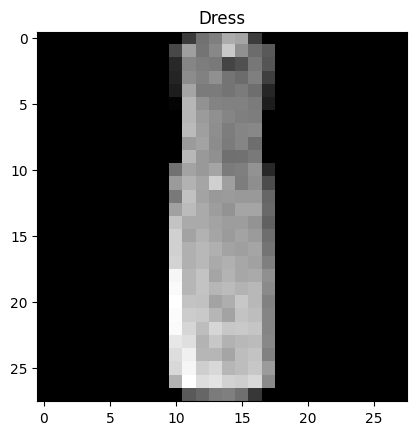

In [ ]:
plt.imshow(test_samples[0].squeeze(), cmap = "gray")
plt.title(train_data.classes[test_labels[0]])

In [ ]:
pred_probs = make_predictions(model = model_2,
                              data = test_samples)

pred_probs[:2]

tensor([[3.1375e-03, 6.0139e-03, 3.4354e-05, 9.8032e-01, 8.2418e-03, 4.7439e-05,
         6.3874e-04, 2.7330e-04, 8.8252e-04, 4.1140e-04],
        [5.3659e-03, 1.4150e-04, 3.5229e-03, 1.2321e-05, 1.1284e-03, 7.3729e-04,
         1.6992e-02, 1.9903e-03, 9.6974e-01, 3.6661e-04]])

In [ ]:
#Convert prediction probabilites to labels
pred_classes = pred_probs.argmax(dim = 1)
pred_classes

tensor([3, 8, 5, 3, 2, 7, 9, 5, 9])

In [ ]:
test_labels

[3, 8, 7, 3, 4, 7, 9, 5, 9]

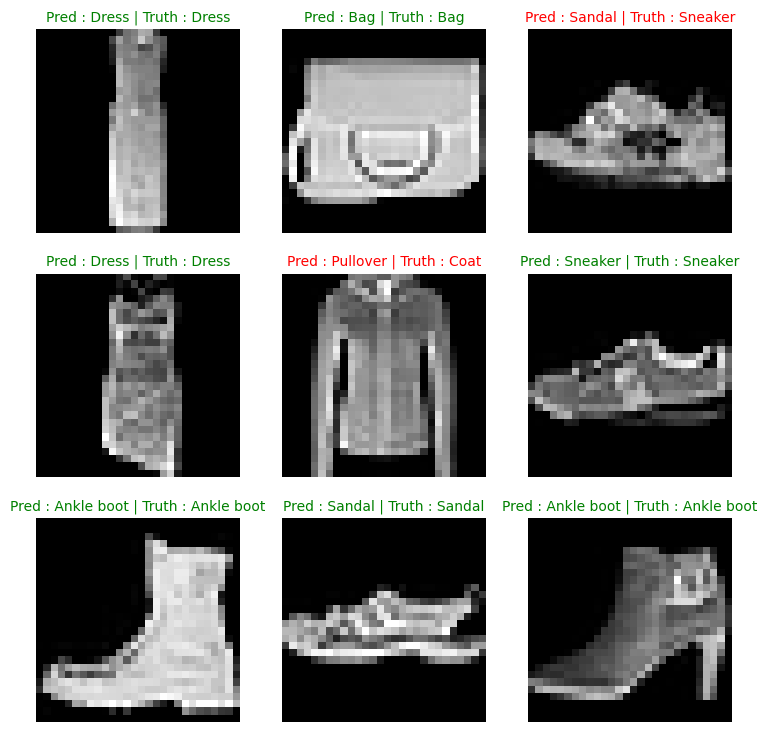

In [ ]:
#Plot predictions
plt.figure(figsize = (9,9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  plt.subplot(nrows, ncols, i+1)
  plt.imshow(sample.squeeze(), cmap = "gray")
  pred_label = train_data.classes[pred_classes[i]]
  truth_label = train_data.classes[test_labels[i]]
  title_text = f"Pred : {pred_label} | Truth : {truth_label}"

  if pred_label == truth_label:
    plt.title(title_text, fontsize = 10, c = "g")
  else:
    plt.title(title_text, fontsize = 10, c = "r")

  plt.axis(False)


 ###Making a confusion matrix for further prediction evaluation

In [ ]:
#import tqdm.auto
from tqdm.auto import tqdm

y_preds = []
model_2.eval()
with torch.inference_mode():
  for X,y in tqdm(test_dataloader, desc = "Making predictions"):
    X,y = X.to(device), y.to(device)
    y_logit = model_2(X)
    y_pred =  torch.softmax(y_logit.squeeze(), dim = 0).argmax(dim = 1)
    y_preds.append(y_pred.cpu())

#concatenate list of predictions into a tensor
# print(y_preds)
y_pred_tensor = torch.cat(y_preds)
y_pred_tensor[:10]


Making predictions:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

In [ ]:
len(y_pred_tensor)

10000

In [ ]:
import mlxtend


In [ ]:
mlxtend.__version__

'0.22.0'

In [ ]:
#see if required packages are installed and if not, install them
!pip install -U torchmetrics


  Using cached torchmetrics-1.3.1-py3-none-any.whl (840 kB)


In [ ]:
assert int(mlxtend.__version__.split(".")[1]) >= 19, "mlxtend version should be 0.19.0 or higher"



In [ ]:
import torchmetrics, mlxtend



In [ ]:
torchmetrics.__version__

'1.3.1'

In [ ]:
mlxtend.__version__


'0.22.0'

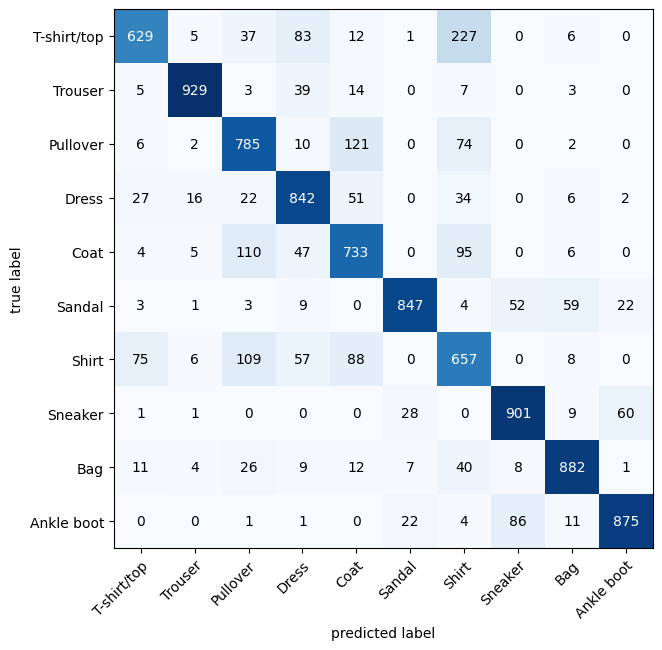

In [ ]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

#setup confusion instance and compare predictions to targets
confmat = ConfusionMatrix(num_classes = len(train_data.classes),
                          task = "Multiclass")
confmat_tensor = confmat(preds = y_pred_tensor,
                         target = test_data.targets)
#plot the confusion matrix
fig, ax = plot_confusion_matrix(conf_mat = confmat_tensor.numpy(),
                      class_names = train_data.classes,
                      figsize = (10,7))


###Save and load best performing model

In [ ]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents = True,
                 exist_ok = True)

MODEL_NAME = "03.pytorch_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

print(f"Saving modeo to : {MODEL_SAVE_PATH}")
torch.save(obj = model_2.state_dict(),
           f = MODEL_SAVE_PATH)

Saving modeo to : models/03.pytorch_computer_vision_model_2.pth


In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

loaded_model_2 = FashionMNISTModelV2(input_shape = 1,
                                   hidden_units = 10,
                                    output_shape = len(train_data.classes))
loaded_model_2.load_state_dict(torch.load(f = MODEL_SAVE_PATH))
loaded_model_2.to(device)



FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [ ]:
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32431334257125854,
 'model_acc': 88.20886581469648}

In [ ]:
#Evalutate loaded model
torch.manual_seed(42)
torch.cuda.manual_seed(42)
loaded_model_2_results = eval_model(model = loaded_model_2,
                                    data_loader = test_dataloader,
                                    loss_fn = loss_fn,
                                    accuracy_fn = accuracy_fn,
                                    device = device)
loaded_model_2_results


  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32431334257125854,
 'model_acc': 88.20886581469648}

In [ ]:
#Check if model results are close to each other
torch.isclose(torch.tensor(model_2_results["model_loss"]),
              torch.tensor(loaded_model_2_results["model_loss"]),
              atol = 1e-02)

tensor(True)